# Tool-Wait Scaling Sweep ($\alpha \in [0, 8]$): Mapping the Three Serving Regimes

Controls all inference tokens and arrivals identically on **Exgentic SWE-bench (`64 GB`, `λ=0.15`, `n=40`)** while scaling every tool-call duration by $\alpha \in \{0.0, 0.5, 1.0, 2.0, 4.0, 8.0\}$:

- **Region 1 ($\alpha = 0$):** Pure active inference — HBM bandwidth saturates; zero `St.TOOL` pool.
- **Region 2 ($\alpha \approx 1$):** Balanced dataset — `B_cap=12` leaves spare HBM to hold `St.TOOL` warm (~90% fewer evictions).
- **Region 3 ($\alpha = 4, 8$):** `St.TOOL` explodes by Little's Law and overflows `64 GB` HBM — testing where `Paged Oracle` separates from `LRU`.

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
from concurrent.futures import ProcessPoolExecutor

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir(os.path.abspath(".."))
sys.path.insert(0, os.getcwd())

from sim.paged_vs_oracle import run_capped_sim

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

trace_path = "data/external_traces/exgentic_swebench.jsonl"
n_req, seed, max_time, rate, hbm = 40, 42, 40000.0, 0.15, 64.0
alphas = [0.0, 0.5, 1.0, 2.0, 4.0, 8.0]

policies = [
    ("Pack (Full LRU)",        "Baseline Full LRU",   {},            "#94a3b8", "s"),
    ("Pack (Paged Oracle)",    "Paged Oracle (JIT)",  {},            "#64748b", "^"),
    ("B_cap=12 + Paged LRU",   "CappedNaivePagedLRU", {"b_cap": 12}, "#f59e0b", "D"),
    ("B_cap=12 + Paged Oracle","CappedPagedOracle",   {"b_cap": 12}, "#2563eb", "o"),
]

tasks = []
for a in alphas:
    for lbl, bp, kw, _, _ in policies:
        kw_a = dict(kw, tool_scale=a)
        tasks.append((f"{a}|{lbl}", bp, hbm, rate, n_req, seed, max_time, trace_path, kw_a))

res = {}
with ProcessPoolExecutor() as ex:
    for k, s in ex.map(run_capped_sim, tasks):
        res[k] = s

hdr = f"{'alpha':5s} | {'Policy':24s} | {'Done':5s} | {'Overhead':9s} | {'Decode/r':8s} | {'Wait/r':8s} | {'TTFTp95':8s} | {'EvictGB':8s} | {'Stall%':6s} | {'ActB':5s} | {'ToolB':5s}"
print(hdr)
print("-" * len(hdr))
for a in alphas:
    for lbl, _, _, _, _ in policies:
        s = res[f"{a}|{lbl}"]
        ss, rs = s["state_seconds"], s["residency_seconds"]
        n = float(s["total_requests"])
        w = max(1e-9, rs["active_wall"])
        tool_r = ss["TOOL"] / n
        overhead = (ss["DECODE"] + ss["PREFILL"] + ss["WAITING"] + ss["STALL"]) / n
        stall_pct = 100.0 * ss["STALL"] / max(1e-9, sum(ss.values()))
        act_b = rs["active_compute"] / w
        tool_b = (rs["tool_full_hbm"] + rs["tool_partial_hbm"] + rs["tool_offloaded_only"]) / w
        print(f"{a:5.1f} | {lbl:24s} | {s['done']:2d}/{s['total_requests']:2d} | {overhead:7.1f} s | "
              f"{ss['DECODE']/n:6.1f} s | {ss['WAITING']/n:6.1f} s | {s['ttft_p95']:6.2f} s | "
              f"{s['total_evicted_gb']:6.1f} G | {stall_pct:5.2f}% | {act_b:5.2f} | {tool_b:5.2f}")
    print("-" * len(hdr))

alpha | Policy                   | Done  | Overhead  | Decode/r | Wait/r   | TTFTp95  | EvictGB  | Stall% | ActB  | ToolB
-------------------------------------------------------------------------------------------------------------------------
  0.0 | Pack (Full LRU)          | 40/40 |  1556.6 s | 1165.6 s |  387.7 s |  10.81 s | 1730.0 G |  0.21% | 13.45 |  0.06
  0.0 | Pack (Paged Oracle)      | 40/40 |  1554.8 s | 1169.6 s |  369.9 s |  12.36 s | 1109.3 G |  0.98% | 13.49 |  0.06
  0.0 | B_cap=12 + Paged LRU     | 40/40 |  1627.5 s |  870.8 s |  756.8 s |   6.93 s |    0.0 G |  0.00% |  9.75 |  0.04
  0.0 | B_cap=12 + Paged Oracle  | 40/40 |  1627.5 s |  870.8 s |  756.8 s |   6.93 s |    0.0 G |  0.00% |  9.75 |  0.04
-------------------------------------------------------------------------------------------------------------------------
  0.5 | Pack (Full LRU)          | 40/40 |  1519.0 s | 1146.3 s |  369.3 s |  19.87 s | 3133.4 G |  0.21% | 13.03 |  1.32
  0.5 | Pack (Paged Orac

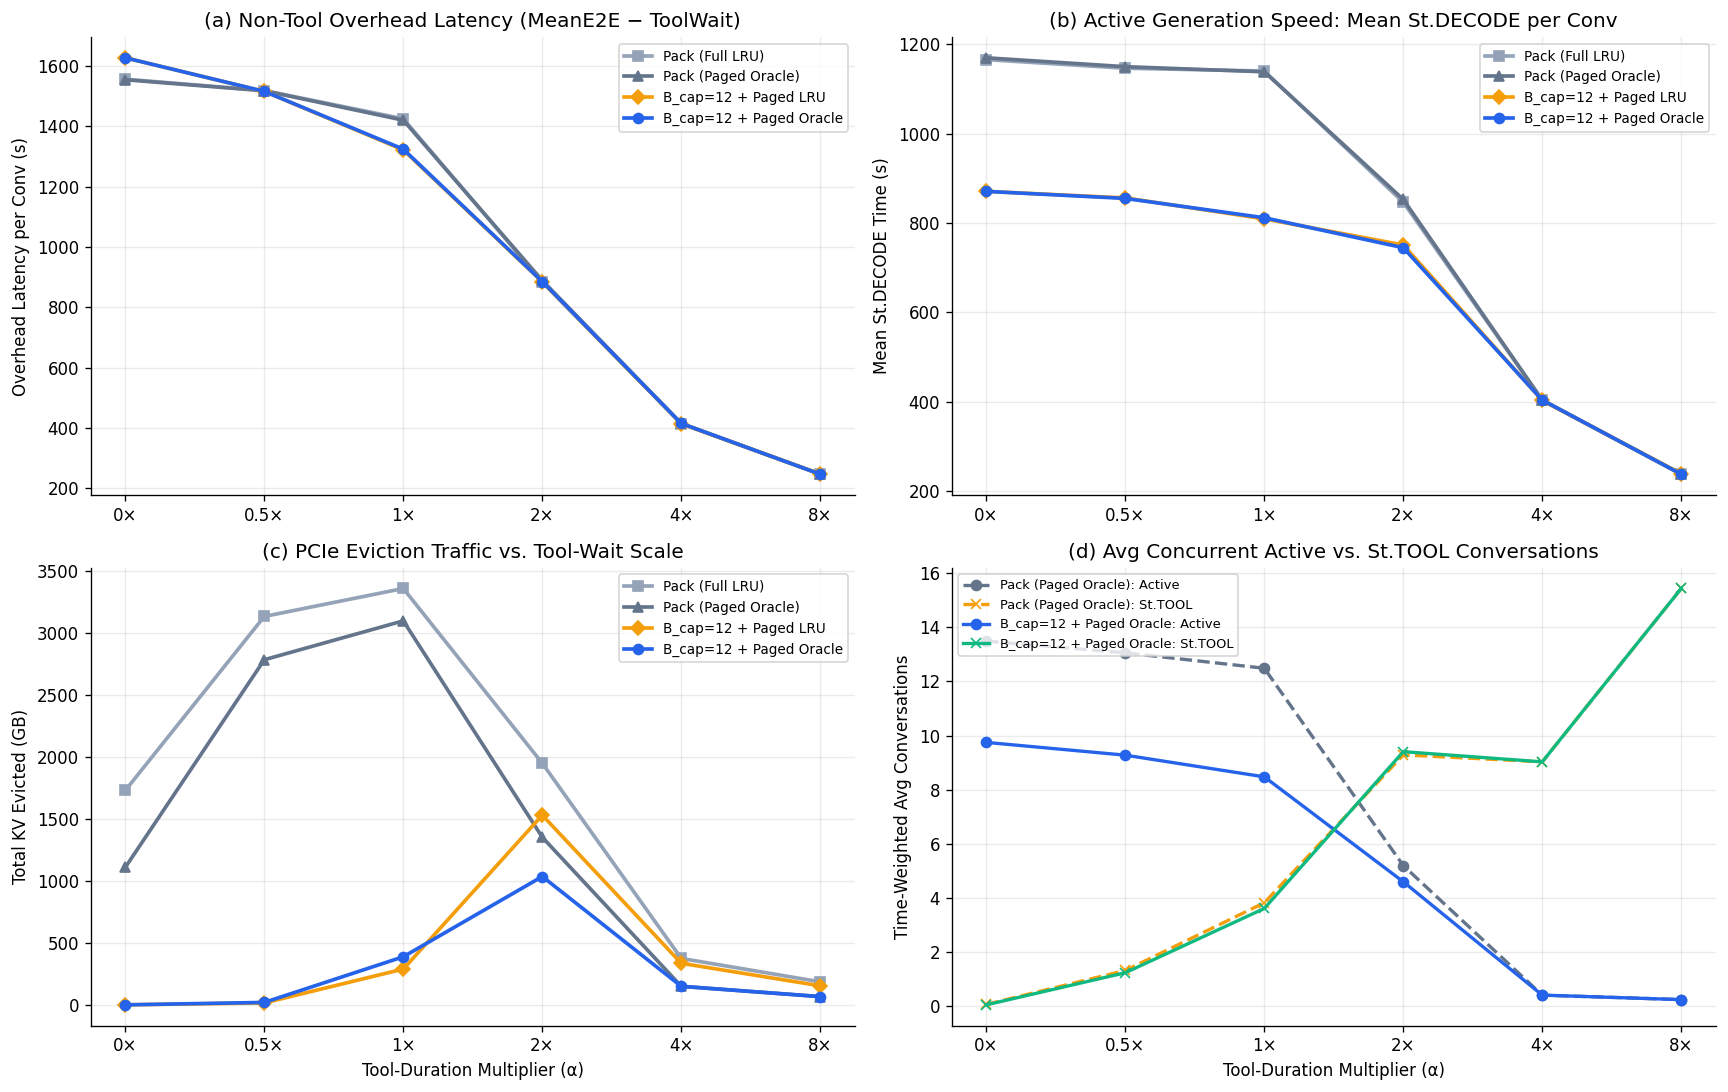

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(14.5, 9.2))
xa = np.arange(len(alphas))
a_lbls = [f"{a:g}×" for a in alphas]

for lbl, _, _, col, mk in policies:
    overheads = [(res[f"{a}|{lbl}"]["state_seconds"]["DECODE"] + res[f"{a}|{lbl}"]["state_seconds"]["PREFILL"] + res[f"{a}|{lbl}"]["state_seconds"]["WAITING"] + res[f"{a}|{lbl}"]["state_seconds"]["STALL"]) / res[f"{a}|{lbl}"]["total_requests"] for a in alphas]
    dec_r = [res[f"{a}|{lbl}"]["state_seconds"]["DECODE"] / res[f"{a}|{lbl}"]["total_requests"] for a in alphas]
    evg = [res[f"{a}|{lbl}"]["total_evicted_gb"] for a in alphas]
    axes[0, 0].plot(xa, overheads, marker=mk, lw=2.2, color=col, label=lbl)
    axes[0, 1].plot(xa, dec_r, marker=mk, lw=2.2, color=col, label=lbl)
    axes[1, 0].plot(xa, evg, marker=mk, lw=2.2, color=col, label=lbl)

axes[0, 0].set_title("(a) Non-Tool Overhead Latency (MeanE2E − ToolWait)")
axes[0, 0].set_ylabel("Overhead Latency per Conv (s)")
axes[0, 0].set_xticks(xa); axes[0, 0].set_xticklabels(a_lbls)
axes[0, 0].legend(fontsize=8.2)

axes[0, 1].set_title("(b) Active Generation Speed: Mean St.DECODE per Conv")
axes[0, 1].set_ylabel("Mean St.DECODE Time (s)")
axes[0, 1].set_xticks(xa); axes[0, 1].set_xticklabels(a_lbls)
axes[0, 1].legend(fontsize=8.2)

axes[1, 0].set_title("(c) PCIe Eviction Traffic vs. Tool-Wait Scale")
axes[1, 0].set_xlabel("Tool-Duration Multiplier (α)")
axes[1, 0].set_ylabel("Total KV Evicted (GB)")
axes[1, 0].set_xticks(xa); axes[1, 0].set_xticklabels(a_lbls)
axes[1, 0].legend(fontsize=8.2)

# (d) Active vs St.TOOL concurrency for Pack (Paged Oracle) vs B_cap=12 + Paged Oracle
for lbl, col, ls in [("Pack (Paged Oracle)", "#64748b", "--"), ("B_cap=12 + Paged Oracle", "#2563eb", "-")]:
    act_arr = [res[f"{a}|{lbl}"]["residency_seconds"]["active_compute"] / max(1e-9, res[f"{a}|{lbl}"]["residency_seconds"]["active_wall"]) for a in alphas]
    tool_arr = [(res[f"{a}|{lbl}"]["residency_seconds"]["tool_full_hbm"] + res[f"{a}|{lbl}"]["residency_seconds"]["tool_partial_hbm"] + res[f"{a}|{lbl}"]["residency_seconds"]["tool_offloaded_only"]) / max(1e-9, res[f"{a}|{lbl}"]["residency_seconds"]["active_wall"]) for a in alphas]
    axes[1, 1].plot(xa, act_arr, marker="o", lw=2.0, ls=ls, color=col, label=f"{lbl}: Active")
    axes[1, 1].plot(xa, tool_arr, marker="x", lw=2.0, ls=ls, color="#10b981" if "B_cap" in lbl else "#f59e0b", label=f"{lbl}: St.TOOL")

axes[1, 1].set_title("(d) Avg Concurrent Active vs. St.TOOL Conversations")
axes[1, 1].set_xlabel("Tool-Duration Multiplier (α)")
axes[1, 1].set_ylabel("Time-Weighted Avg Conversations")
axes[1, 1].set_xticks(xa); axes[1, 1].set_xticklabels(a_lbls)
axes[1, 1].legend(fontsize=7.8, loc="upper left")

plt.tight_layout()
plt.show()